# 03b · Anomaly detection without Spark (scikit-learn)
The same K-Means (same k, `max_iter=20`, one init, same standardised log-features) on **exactly the same rows** as `03a`, but on a single machine with scikit-learn/pandas. Also runs Isolation Forest as an extra, non-clustering detector.

Compare against `ml/outputs/03a_metrics.json`. Metrics go to `ml/outputs/03b_metrics.json`. Run `03a` first (it creates `data/gold/sf_log_5m`).

In [1]:
import os, json, time, subprocess, sys, resource, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr

DATA, OUT, FIG = "/home/jovyan/work/data", "/home/jovyan/work/ml/outputs", "/home/jovyan/work/laporan/gambar"
GOLD = f"{DATA}/gold"
SEED, MAXITER = 42, 20
spark_m = json.load(open(f"{OUT}/03a_metrics.json"))
K = spark_m["k"]; print("k from 03a =", K)
FEATS = ["n_events","n_view","n_cart","n_purchase","n_products","n_categories","n_brands",
         "duration_sec","events_per_min","avg_gap_sec","cart_per_view","purchase_per_view",
         "purchase_per_cart","avg_price","purchase_value","purchase_no_view"]
metrics = {}
rss_mb = lambda: resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 / 1024  # Linux: KB -> GB

k from 03a = 6


## 1. Load the shared 5M sample into pandas

In [2]:
t0 = time.time()
df = pd.read_parquet(f"{GOLD}/sf_log_5m", columns=["rn"] + FEATS).sort_values("rn").reset_index(drop=True)
print(df.shape, f"loaded in {time.time()-t0:.1f}s, peak RSS so far {rss_mb():.2f} GB")

(5000000, 17) loaded in 0.3s, peak RSS so far 3.01 GB


## 2. Scalability: same sizes as Spark
Sizes run in ascending order, so the *peak RSS* column (process high-water mark) is non-decreasing and reflects the largest size reached so far.

In [3]:
rows = []
for n in [100_000, 500_000, 1_000_000, 2_000_000, 5_000_000]:
    X = StandardScaler().fit_transform(df.loc[df.rn <= n, FEATS].to_numpy())
    t0 = time.time()
    km = KMeans(n_clusters=K, n_init=1, max_iter=MAXITER, random_state=SEED, algorithm="lloyd").fit(X)
    dt = time.time() - t0
    rows.append(dict(n=n, fit_s=round(dt, 1), wssse_per_row=km.inertia_ / n, iters=int(km.n_iter_), peak_rss_gb=round(rss_mb(), 2)))
    print(rows[-1])
metrics["scalability"] = rows

{'n': 100000, 'fit_s': 0.1, 'wssse_per_row': 5.1960350068464205, 'iters': 10, 'peak_rss_gb': 3.01}


{'n': 500000, 'fit_s': 0.2, 'wssse_per_row': 5.24006453212817, 'iters': 16, 'peak_rss_gb': 3.01}


{'n': 1000000, 'fit_s': 0.4, 'wssse_per_row': 5.6257994513026, 'iters': 15, 'peak_rss_gb': 3.01}


{'n': 2000000, 'fit_s': 0.6, 'wssse_per_row': 4.91398557539698, 'iters': 20, 'peak_rss_gb': 3.13}


{'n': 5000000, 'fit_s': 1.2, 'wssse_per_row': 5.701467541127345, 'iters': 13, 'peak_rss_gb': 3.13}


## 3. Full data (22.99M sessions) in an isolated process
A single-machine run on the full table is done in a subprocess so that an out-of-memory kill is recorded instead of crashing the notebook kernel. Container memory limit is 16 GB.

In [4]:
script = textwrap.dedent(f'''
    import time, json, resource, numpy as np, pandas as pd
    from sklearn.cluster import KMeans
    from sklearn.preprocessing import StandardScaler
    FEATS = {FEATS!r}
    t0 = time.time()
    d = pd.read_parquet("{GOLD}/session_features", columns=FEATS)
    X = np.log1p(d.to_numpy(dtype="float64")); del d
    X = StandardScaler().fit_transform(X)
    t_prep = time.time() - t0
    t0 = time.time()
    km = KMeans(n_clusters={K}, n_init=1, max_iter={MAXITER}, random_state={SEED}, algorithm="lloyd").fit(X)
    print(json.dumps(dict(n=len(X), prep_s=round(t_prep,1), fit_s=round(time.time()-t0,1), wssse_per_row=km.inertia_/len(X),
          iters=int(km.n_iter_), peak_rss_gb=round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024/1024,2))))
''')
t0 = time.time()
p = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True)
if p.returncode == 0:
    full = json.loads(p.stdout.strip().splitlines()[-1]); full["status"] = "ok"
else:
    full = dict(status=f"failed (return code {p.returncode}; -9 = killed by OOM)", wall_s=round(time.time()-t0, 1), stderr=p.stderr[-300:])
metrics["full"] = full; print(full)

{'n': 22995676, 'prep_s': 3.1, 'fit_s': 4.4, 'wssse_per_row': 5.2288368880261595, 'iters': 11, 'peak_rss_gb': 9.26, 'status': 'ok'}


## 4. Isolation Forest (extra detector, 1M sample)
Tree-based, no distance to a centroid. Compared with the K-Means distance score on the same rows: Spearman rank correlation of scores and overlap (Jaccard) of the top 0.5%.

In [5]:
n = 1_000_000
X = StandardScaler().fit_transform(df.loc[df.rn <= n, FEATS].to_numpy())
t0 = time.time()
iso = IsolationForest(n_estimators=100, max_samples=256, n_jobs=-1, random_state=SEED).fit(X)
iso_score = -iso.score_samples(X); t_iso = time.time() - t0
km = KMeans(n_clusters=K, n_init=1, max_iter=MAXITER, random_state=SEED, algorithm="lloyd").fit(X)
km_score = np.sqrt(((X - km.cluster_centers_[km.labels_]) ** 2).sum(axis=1))
top = lambda s: set(np.argsort(s)[-int(0.005 * len(s)):])
a, b = top(iso_score), top(km_score)
metrics["isolation_forest"] = dict(n=n, fit_and_score_s=round(t_iso, 1),
    spearman=float(spearmanr(iso_score, km_score)[0]), jaccard_top05=len(a & b) / len(a | b))
metrics["isolation_forest"]

{'n': 1000000,
 'fit_and_score_s': 2.2,
 'spearman': 0.7476115782309657,
 'jaccard_top05': 0.24362641462504664}

## 5. Comparison with the Spark run

,n,fit_s_sk,wssse_per_row_sk,iters_sk,peak_rss_gb_sk,fit_s_spark,wssse_per_row_spark,iters_spark,speedup_spark_vs_sk
0,100000,0.1,5.196,10.0,3.01,1.3,5.196,20,0.077
1,500000,0.2,5.240,16.0,3.01,5.1,5.249,20,0.039
2,1000000,0.4,5.626,15.0,3.01,9.9,4.916,20,0.040
3,2000000,0.6,4.914,20.0,3.13,19.8,5.328,20,0.030
4,5000000,1.2,5.701,13.0,3.13,21.9,5.617,20,0.055
5,22995676,NaN,NaN,NaN,NaN,50.3,4.568,17,NaN


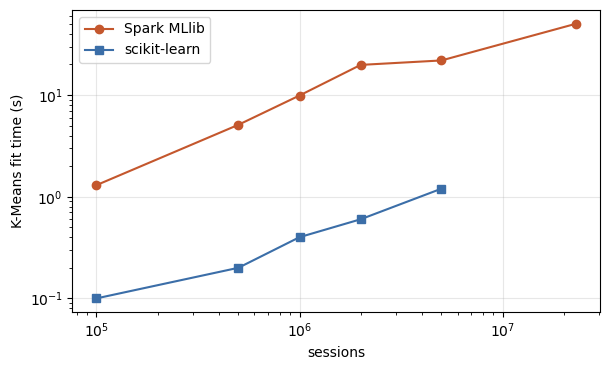

In [6]:
sp = pd.DataFrame(spark_m["scalability"]).rename(columns=lambda c: c + "_spark" if c != "n" else c)
sk = pd.DataFrame(metrics["scalability"]).rename(columns=lambda c: c + "_sk" if c != "n" else c)
cmp_ = sk.merge(sp, on="n", how="outer").sort_values("n")
cmp_["speedup_spark_vs_sk"] = cmp_.fit_s_sk / cmp_.fit_s_spark
display(cmp_.round(3)); metrics["comparison"] = cmp_.to_dict(orient="records")

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(cmp_.n, cmp_.fit_s_spark, "o-", label="Spark MLlib", color="#c4572d")
ax.plot(cmp_.n, cmp_.fit_s_sk, "s-", label="scikit-learn", color="#3b6ea8")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("sessions"); ax.set_ylabel("K-Means fit time (s)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG}/fig_5_4_kmeans_scalability.png", dpi=160); plt.show()
json.dump(metrics, open(f"{OUT}/03b_metrics.json", "w"), indent=2, default=str)